# Mini2P stripe-noise removal utilities

This notebook is designed for large TIFF stacks that may crash the kernel if fully loaded into RAM.

It assumes your raw TIFF is saved as:

```python
frames x height x width
```

For your file, this looked like:

```python
(21820, 512, 512)
```

The interleaved channels are assumed to be:

```python
channel 0 = frames 0, 2, 4, ...
channel 1 = frames 1, 3, 5, ...
```

Change `signal_channel` and `reference_channel` if needed.

## Option 2: Same-channel background-based stripe subtraction

This avoids using the structural red channel.

It estimates the stripe pattern only from dim/background pixels in the GCaMP channel itself. This should preserve signal better than subtracting row or column means from the whole image.

This is also intended for **vertical stripe noise**. If your stripes are horizontal, set `stripe_axis = "row"`.

In [1]:
import os
import gc
import numpy as np
import tifffile
import matplotlib.pyplot as plt

# ----------------------------
# User settings
# ----------------------------
path = "/Users/megyoung/Desktop/mini2p Images/72Lgoodtask"  # CHANGE THIS
selected_tiff = "72ltask_00001.tif"  # CHANGE THIS if needed

tiff_path = os.path.join(path, selected_tiff)

# Which interleaved channel is GCaMP / functional?
# 0 means raw frames 0, 2, 4, ...
# 1 means raw frames 1, 3, 5, ...
signal_channel = 1

# Which interleaved channel is structural red/reference?
reference_channel = 0

# Processing size. Lower if kernel crashes.
chunk_size = 25

# Output
base = os.path.splitext(selected_tiff)[0]

In [2]:
# ----------------------------
# Inspect TIFF without loading whole thing
# ----------------------------
with tifffile.TiffFile(tiff_path) as tif:
    n_pages = len(tif.pages)
    height, width = tif.pages[0].shape
    dtype = tif.pages[0].dtype

print("Raw frames:", n_pages)
print("Height:", height)
print("Width:", width)
print("dtype:", dtype)

n_signal_frames = len(np.arange(signal_channel, n_pages, 2))
n_reference_frames = len(np.arange(reference_channel, n_pages, 2))

print("Signal frames:", n_signal_frames)
print("Reference frames:", n_reference_frames)

Raw frames: 21820
Height: 512
Width: 512
dtype: int16
Signal frames: 10910
Reference frames: 10910


In [3]:
def read_pages_from_open_tif(tif, frame_indices):
    # Read selected TIFF pages into array shaped frames x height x width.
    return np.stack([tif.pages[int(i)].asarray() for i in frame_indices], axis=0)


def robust_rescale_for_display(img, low=1, high=99):
    img = img.astype(np.float32)
    vmin, vmax = np.nanpercentile(img, [low, high])
    return np.clip((img - vmin) / (vmax - vmin + 1e-8), 0, 1)


def preview_interleaved_channel(tiff_path, channel, n_frames=200):
    with tifffile.TiffFile(tiff_path) as tif:
        n_pages = len(tif.pages)
        inds = np.arange(channel, min(n_pages, channel + 2 * n_frames), 2)
        chunk = read_pages_from_open_tif(tif, inds).astype(np.float32)

    mean_img = np.mean(chunk, axis=0)
    del chunk
    gc.collect()
    return mean_img


def write_chunk(writer, chunk, output_dtype=np.float32):
    # tifffile writes chunk as a multi-page stack.
    # chunk shape: frames x height x width
    writer.write(chunk.astype(output_dtype), photometric="minisblack")

In [4]:
# ----------------------------
# Raw channel previews
# ----------------------------
sig_preview = preview_interleaved_channel(tiff_path, signal_channel, n_frames=200)
ref_preview = preview_interleaved_channel(tiff_path, reference_channel, n_frames=200)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(robust_rescale_for_display(sig_preview), cmap="gray")
plt.title("Raw signal / GCaMP preview")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(robust_rescale_for_display(ref_preview), cmap="gray")
plt.title("Raw structural/reference preview")
plt.axis("off")

plt.show()

KeyboardInterrupt: 

In [ ]:
# ----------------------------
# Background-based stripe subtraction settings
# ----------------------------

# "column" for vertical stripes; "row" for horizontal stripes
stripe_axis = "column"

# Pixels below this percentile are treated as likely background.
# Try 10, 20, 30.
background_percentile = 20

# Correction strength.
# Start conservative. Try 0.5, 0.75, 1.0.
correction_strength = 0.75

# Smooth stripe profile across columns/rows.
smooth_window = 5

output_file = os.path.join(path, f"{base}_unstriped_background_ch{signal_channel}.tiff")
print("Output:", output_file)

Output: /Users/megyoung/Desktop/mini2p Images/72Lgoodtask/72ltask_00001_unstriped_background_ch1.tiff


In [ ]:
def moving_average_1d(x, window=5):
    if window <= 1:
        return x
    kernel = np.ones(window, dtype=np.float32) / window
    return np.convolve(x, kernel, mode="same")


def fill_nan_profile(profile):
    x = np.arange(profile.size)
    good = np.isfinite(profile)
    if np.sum(good) == 0:
        return np.zeros_like(profile, dtype=np.float32)
    if np.sum(good) == 1:
        return np.full_like(profile, profile[good][0], dtype=np.float32)
    return np.interp(x, x[good], profile[good]).astype(np.float32)


def estimate_background_stripe_profile(frame, axis="column", background_percentile=20, smooth_window=5):
    # Estimate stripe profile from dim/background pixels only.
    frame = frame.astype(np.float32)
    thresh = np.nanpercentile(frame, background_percentile)
    background_mask = frame <= thresh

    if axis == "column":
        n = frame.shape[1]
        profile = np.full(n, np.nan, dtype=np.float32)

        for x in range(n):
            vals = frame[:, x][background_mask[:, x]]
            if vals.size > 0:
                profile[x] = np.nanmedian(vals)

    elif axis == "row":
        n = frame.shape[0]
        profile = np.full(n, np.nan, dtype=np.float32)

        for y in range(n):
            vals = frame[y, :][background_mask[y, :]]
            if vals.size > 0:
                profile[y] = np.nanmedian(vals)

    else:
        raise ValueError("axis must be 'column' or 'row'")

    profile = fill_nan_profile(profile)
    profile = profile - np.nanmedian(profile)

    if smooth_window > 1:
        profile = moving_average_1d(profile, smooth_window)

    return profile.astype(np.float32)


def correct_chunk_background(signal_chunk, axis="column",
                             background_percentile=20,
                             smooth_window=5,
                             correction_strength=0.75):
    signal_chunk = signal_chunk.astype(np.float32)
    corrected = np.empty_like(signal_chunk, dtype=np.float32)

    for i in range(signal_chunk.shape[0]):
        frame = signal_chunk[i]
        profile = estimate_background_stripe_profile(
            frame,
            axis=axis,
            background_percentile=background_percentile,
            smooth_window=smooth_window
        )

        if axis == "column":
            corrected[i] = frame - correction_strength * profile[None, :]
        else:
            corrected[i] = frame - correction_strength * profile[:, None]

    return corrected


def run_background_subtraction(tiff_path, signal_channel, output_file,
                               chunk_size=25,
                               axis="column",
                               background_percentile=20,
                               smooth_window=5,
                               correction_strength=0.75,
                               output_dtype=np.float32):
    with tifffile.TiffFile(tiff_path) as tif:
        n_pages = len(tif.pages)
        signal_frames = np.arange(signal_channel, n_pages, 2)
        n = len(signal_frames)

        with tifffile.TiffWriter(output_file, bigtiff=True) as writer:
            for start in range(0, n, chunk_size):
                end = min(start + chunk_size, n)
                inds = signal_frames[start:end]

                signal_chunk = read_pages_from_open_tif(tif, inds)

                corrected = correct_chunk_background(
                    signal_chunk,
                    axis=axis,
                    background_percentile=background_percentile,
                    smooth_window=smooth_window,
                    correction_strength=correction_strength
                )

                write_chunk(writer, corrected, output_dtype=output_dtype)

                print(f"Saved corrected frames {start} to {end} / {n}")

                del signal_chunk, corrected
                gc.collect()

In [ ]:
run_background_subtraction(
    tiff_path=tiff_path,
    signal_channel=signal_channel,
    output_file=output_file,
    chunk_size=chunk_size,
    axis=stripe_axis,
    background_percentile=background_percentile,
    smooth_window=smooth_window,
    correction_strength=correction_strength,
    output_dtype=np.float32
)

print("Done.")
print("Saved:", output_file)

Saved corrected frames 0 to 25 / 10910
Saved corrected frames 25 to 50 / 10910
Saved corrected frames 50 to 75 / 10910
Saved corrected frames 75 to 100 / 10910
Saved corrected frames 100 to 125 / 10910
Saved corrected frames 125 to 150 / 10910
Saved corrected frames 150 to 175 / 10910
Saved corrected frames 175 to 200 / 10910
Saved corrected frames 200 to 225 / 10910
Saved corrected frames 225 to 250 / 10910
Saved corrected frames 250 to 275 / 10910
Saved corrected frames 275 to 300 / 10910
Saved corrected frames 300 to 325 / 10910
Saved corrected frames 325 to 350 / 10910
Saved corrected frames 350 to 375 / 10910
Saved corrected frames 375 to 400 / 10910
Saved corrected frames 400 to 425 / 10910
Saved corrected frames 425 to 450 / 10910
Saved corrected frames 450 to 475 / 10910
Saved corrected frames 475 to 500 / 10910
Saved corrected frames 500 to 525 / 10910
Saved corrected frames 525 to 550 / 10910
Saved corrected frames 550 to 575 / 10910
Saved corrected frames 575 to 600 / 10910


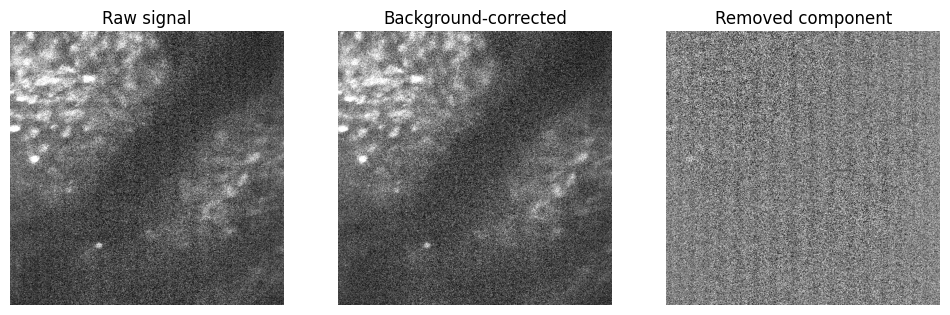

In [ ]:
# ----------------------------
# Preview corrected output
# ----------------------------
corrected_preview = preview_interleaved_channel(output_file, channel=0, n_frames=200)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(robust_rescale_for_display(sig_preview), cmap="gray")
plt.title("Raw signal")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(robust_rescale_for_display(corrected_preview), cmap="gray")
plt.title("Background-corrected")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(robust_rescale_for_display(sig_preview - corrected_preview), cmap="gray")
plt.title("Removed component")
plt.axis("off")

plt.show()

In [ ]:
from pathlib import Path
import csv
import numpy as np


# ----------------------------
# Paths
# ----------------------------
PLANE_DIR = Path("/Users/megyoung/Desktop/mini2p Images/distdetrd/suite2p/plane0")

GREEN_SEG = PLANE_DIR / "meanImg_ch1_seg.npy"
GREEN_BIN = PLANE_DIR / "data.bin"

OUT_DIR = PLANE_DIR / "custom_green_mask_traces"
OUT_DIR.mkdir(parents=True, exist_ok=True)


# ----------------------------
# Settings
# ----------------------------
CHUNK_SIZE = 500
BASELINE_PERCENTILE = 20.0


# ----------------------------
# Functions
# ----------------------------
def load_cellpose_masks(seg_path):
    seg = np.load(seg_path, allow_pickle=True).item()

    if "masks" not in seg:
        raise KeyError(f"No 'masks' array found in {seg_path}")

    masks = np.asarray(seg["masks"])

    if masks.ndim != 2:
        raise ValueError(f"Expected 2D masks in {seg_path}, got shape {masks.shape}")

    return masks


def masks_to_rois(mask_image):
    rois = []

    for mask_id in sorted(int(v) for v in np.unique(mask_image) if v > 0):
        ypix, xpix = np.nonzero(mask_image == mask_id)

        if len(ypix) == 0:
            continue

        rois.append(
            {
                "source_mask_id": mask_id,
                "ypix": ypix.astype(np.int64),
                "xpix": xpix.astype(np.int64),
                "lam": np.ones(len(ypix), dtype=np.float32),
                "npix": int(len(ypix)),
                "med": np.array(
                    [np.median(ypix), np.median(xpix)],
                    dtype=np.float32,
                ),
            }
        )

    return rois


def suite2p_stat_from_rois(rois):
    stat = []

    for roi in rois:
        stat.append(
            {
                "ypix": roi["ypix"],
                "xpix": roi["xpix"],
                "lam": roi["lam"],
                "npix": roi["npix"],
                "med": roi["med"],
                "source_mask_id": roi["source_mask_id"],
            }
        )

    return np.asarray(stat, dtype=object)


def extract_f_traces(movie, rois, chunk_size=500):
    n_frames = movie.shape[0]
    f = np.zeros((len(rois), n_frames), dtype=np.float32)

    for start in range(0, n_frames, chunk_size):
        stop = min(start + chunk_size, n_frames)
        chunk = movie[start:stop]

        for roi_i, roi in enumerate(rois):
            pixels = chunk[:, roi["ypix"], roi["xpix"]]
            f[roi_i, start:stop] = pixels.mean(axis=1)

        print(f"Extracted {stop}/{n_frames} frames")

    return f


def calculate_dff(f, baseline_percentile=20.0):
    f0 = np.percentile(f, baseline_percentile, axis=1, keepdims=True)
    f0 = np.maximum(f0, 1e-6)
    dff = (f - f0) / f0

    return f0[:, 0], dff.astype(np.float32)


def save_roi_table(path, rois):
    with path.open("w", newline="") as handle:
        writer = csv.DictWriter(
            handle,
            fieldnames=["roi_id", "source_mask_id", "npix", "med_y", "med_x"],
        )

        writer.writeheader()

        for roi_id, roi in enumerate(rois):
            writer.writerow(
                {
                    "roi_id": roi_id,
                    "source_mask_id": roi["source_mask_id"],
                    "npix": roi["npix"],
                    "med_y": float(roi["med"][0]),
                    "med_x": float(roi["med"][1]),
                }
            )


# ----------------------------
# Load Suite2p ops
# ----------------------------
ops = np.load(PLANE_DIR / "ops.npy", allow_pickle=True).item()

ly = int(ops["Ly"])
lx = int(ops["Lx"])

print("Suite2p frame shape:", (ly, lx))


# ----------------------------
# Load green Cellpose masks
# ----------------------------
green_masks = load_cellpose_masks(GREEN_SEG)

print("Green mask shape:", green_masks.shape)
print("Number of green ROIs:", int(green_masks.max()))

if green_masks.shape != (ly, lx):
    raise ValueError(
        f"Green masks shape {green_masks.shape} does not match Suite2p frame shape {(ly, lx)}"
    )


# ----------------------------
# Convert masks to ROIs
# ----------------------------
rois = masks_to_rois(green_masks)

if not rois:
    raise ValueError("No ROIs found in green Cellpose masks")

print("ROIs to extract:", len(rois))


# ----------------------------
# Load registered green binary
# ----------------------------
n_frames = GREEN_BIN.stat().st_size // (
    np.dtype("int16").itemsize * ly * lx
)

if n_frames == 0:
    raise ValueError(f"No frames found in {GREEN_BIN}")

movie = np.memmap(
    GREEN_BIN,
    dtype="int16",
    mode="r",
    shape=(n_frames, ly, lx),
)

print("Green binary:", GREEN_BIN)
print("Movie shape:", movie.shape)


# ----------------------------
# Extract traces
# ----------------------------
f = extract_f_traces(
    movie,
    rois,
    chunk_size=CHUNK_SIZE,
)


# ----------------------------
# Calculate dF/F
# ----------------------------
f0, dff = calculate_dff(
    f,
    baseline_percentile=BASELINE_PERCENTILE,
)


# ----------------------------
# Save outputs
# ----------------------------
np.save(OUT_DIR / "F.npy", f)
np.save(OUT_DIR / "F0.npy", f0)
np.save(OUT_DIR / "dff.npy", dff)
np.save(OUT_DIR / "stat.npy", suite2p_stat_from_rois(rois))
np.save(OUT_DIR / "iscell.npy", np.column_stack([np.ones(len(rois)), np.ones(len(rois))]))

save_roi_table(OUT_DIR / "roi_table.csv", rois)

print("Saved outputs to:", OUT_DIR)

Suite2p frame shape: (512, 512)
Green mask shape: (512, 512)
Number of green ROIs: 289
ROIs to extract: 289
Green binary: /Users/megyoung/Desktop/mini2p Images/distdetrd/suite2p/plane0/data.bin
Movie shape: (500, 512, 512)
Extracted 500/500 frames
Saved outputs to: /Users/megyoung/Desktop/mini2p Images/distdetrd/suite2p/plane0/custom_green_mask_traces


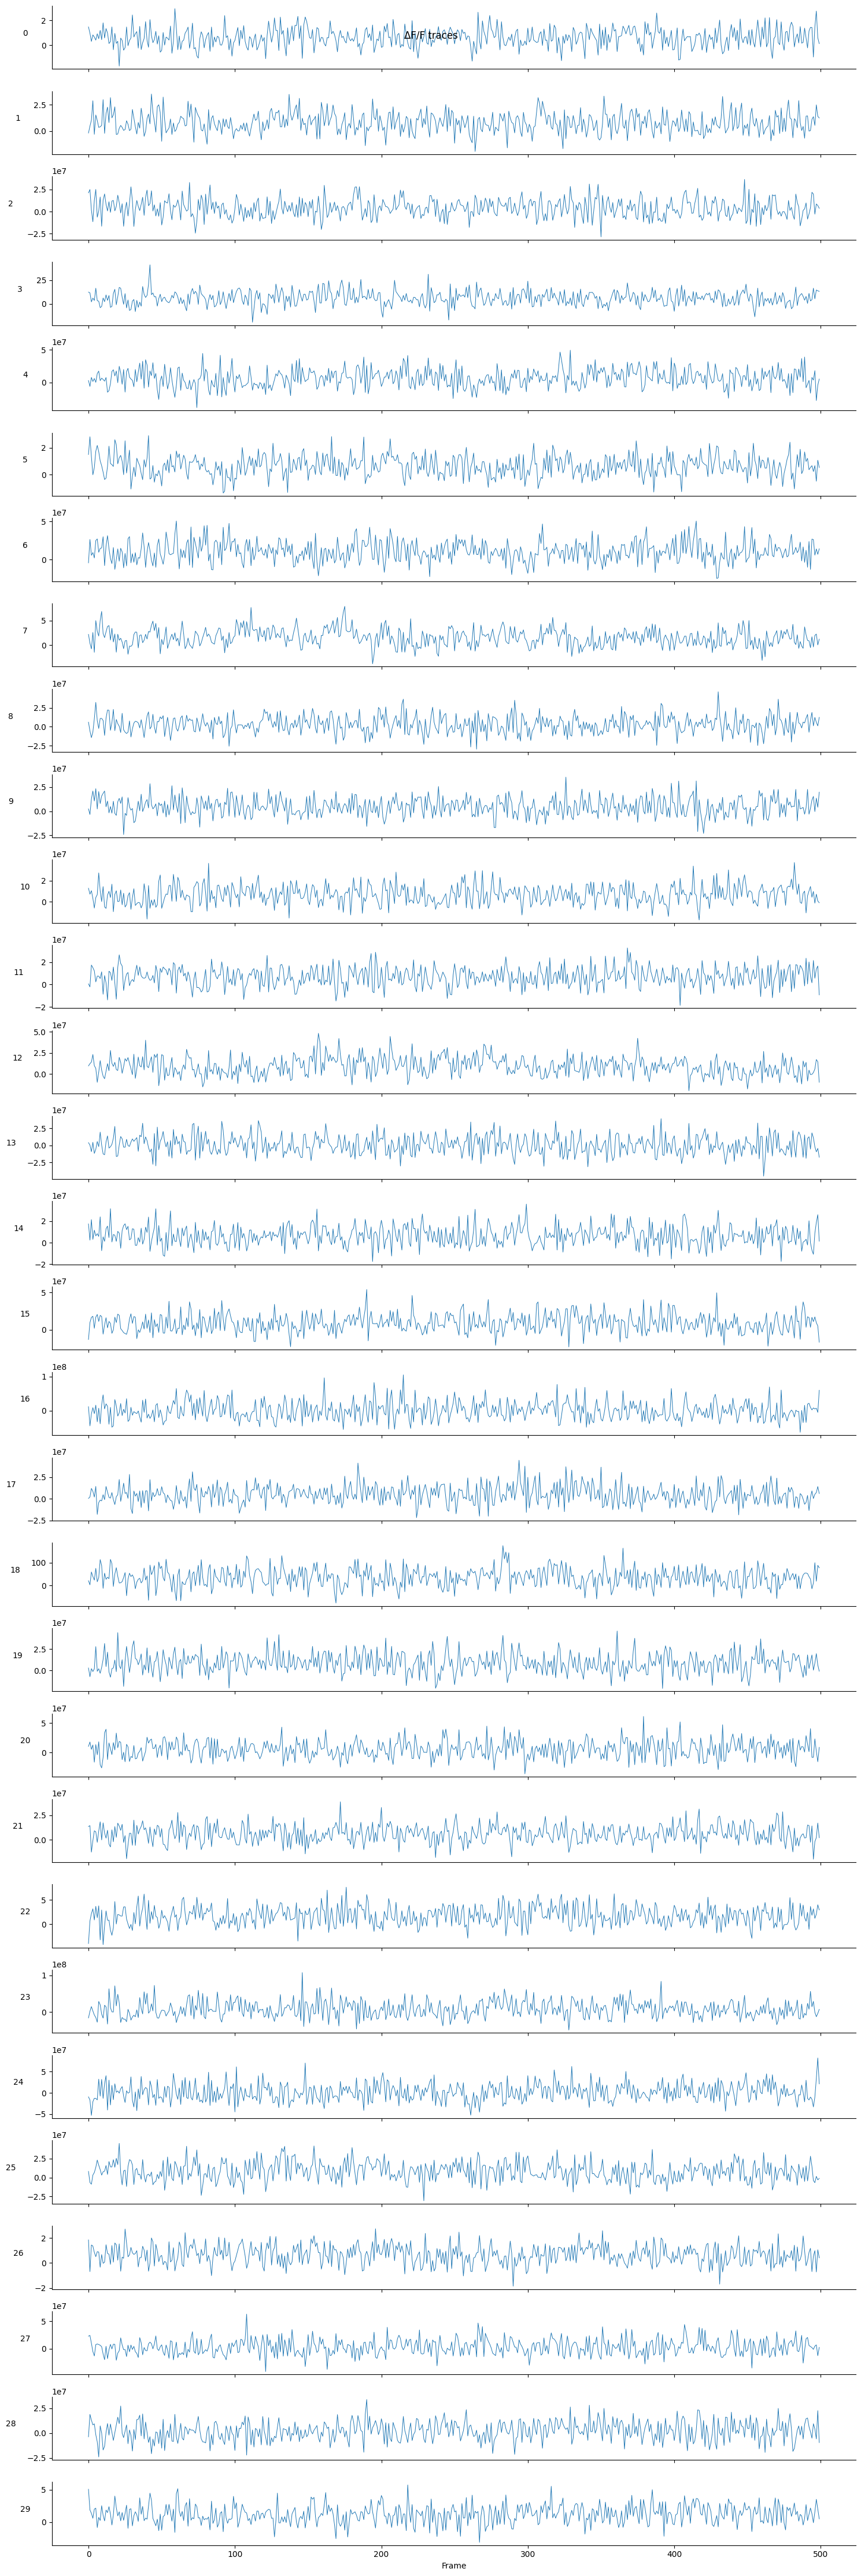

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Load dF/F traces
dff = np.load(OUT_DIR / "dff.npy")

# Choose which ROIs to plot
rois_to_plot = np.arange(30)  # first 30 ROIs

fig, axes = plt.subplots(
    len(rois_to_plot),
    1,
    figsize=(15, 1.5 * len(rois_to_plot)),
    sharex=True
)

# Handle case of only one ROI
if len(rois_to_plot) == 1:
    axes = [axes]

for ax, roi in zip(axes, rois_to_plot):
    ax.plot(dff[roi], lw=0.7)
    ax.set_ylabel(f"{roi}", rotation=0, labelpad=20)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

axes[-1].set_xlabel("Frame")
plt.suptitle("ΔF/F traces")
plt.tight_layout()
plt.show()